# M2 - Séquence Vidéo - TP Calibration de Caméra avec OpenCV

In [1]:
import numpy as np
import cv2
import glob
import os
import matplotlib.pyplot as plt

### 1. Configuration des paramètres

In [2]:
# Paramètres de la grille
colonnes_internes = 5
lignes_internes = 5
taille_carre_m = 0.02  # exactement 2cm mesuré

# Préparation des points 3D
objp = np.zeros((colonnes_internes * lignes_internes, 3), np.float32)
objp[:, :2] = np.mgrid[0:colonnes_internes, 0:lignes_internes].T.reshape(-1, 2)
objp *= taille_carre_m

objpoints = [] 
imgpoints = []

### 2. Détection des coins sur les images

In [3]:
images = glob.glob('data_augmented/*.jpeg') 

if not images:
    print("Aucune image trouvée dans le dossier 'data'.")
else:
    print(f"{len(images)} images trouvées")

shape_img = None
succes_count = 0

# Création d'un dossier pour sauvegarder les images avec les coins tracés (optionnel mais utile)
if not os.path.exists('data_debug_augmented'):
    os.makedirs('data_debug_augmented')

for fname in images:
    print(f"\n[Traitement] Lecture de {fname}...")
    img = cv2.imread(fname)
    
    if img is None:
        print(f"ERREUR : Impossible de lire l'image {fname}.")
        continue
        
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    if shape_img is None:
        shape_img = gray.shape[::-1]
        print(f"  -> Résolution de l'image fixée à : {shape_img[0]}x{shape_img[1]} pixels")

    # Trouver les coins
    ret, corners = cv2.findChessboardCorners(gray, (colonnes_internes, lignes_internes), None)

    if ret:
        objpoints.append(objp)
        corners2 = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1),
                                    (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001))
        imgpoints.append(corners2)
        succes_count += 1
        print(f"  -> SUCCÈS : 25 coins détectés et affinés.")
        
        # Dessiner et sauvegarder pour vérification
        cv2.drawChessboardCorners(img, (colonnes_internes, lignes_internes), corners2, ret)
        debug_path = os.path.join('data_debug', os.path.basename(fname))
        cv2.imwrite(debug_path, img)
        print(f"  -> Image de debug sauvegardée dans {debug_path}")
    else:
        print(f"ÉCHEC : Les coins n'ont pas pu être détectés (problème d'angle, de flou, ou grille incomplète).")

print(f"\nFIN DU TRAITEMENT : {succes_count}/{len(images)} images valides")

91 images trouvées

[Traitement] Lecture de data_augmented\WhatsApp Image 2026-11-05 at 14.13.22.jpeg...
  -> Résolution de l'image fixée à : 1920x1080 pixels
  -> SUCCÈS : 25 coins détectés et affinés.
  -> Image de debug sauvegardée dans data_debug\WhatsApp Image 2026-11-05 at 14.13.22.jpeg

[Traitement] Lecture de data_augmented\WhatsApp Image 2026-11-05 at 14.13.26.jpeg...
  -> SUCCÈS : 25 coins détectés et affinés.
  -> Image de debug sauvegardée dans data_debug\WhatsApp Image 2026-11-05 at 14.13.26.jpeg

[Traitement] Lecture de data_augmented\WhatsApp Image 2026-11-05 at 14.13.27.jpeg...
  -> SUCCÈS : 25 coins détectés et affinés.
  -> Image de debug sauvegardée dans data_debug\WhatsApp Image 2026-11-05 at 14.13.27.jpeg

[Traitement] Lecture de data_augmented\WhatsApp Image 2026-11-05 at 14.13.28.jpeg...
  -> SUCCÈS : 25 coins détectés et affinés.
  -> Image de debug sauvegardée dans data_debug\WhatsApp Image 2026-11-05 at 14.13.28.jpeg

[Traitement] Lecture de data_augmented\Wha

### 3. Calibration et calcul de la focale physique

In [4]:
if succes_count > 0:
    print("\nLancement de l'algorithme de calibration OpenCV...")
    ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, shape_img, None, None)

    print("\n--- RÉSULTATS DE LA CALIBRATION ---")
    print("Matrice intrinsèque (mtx) :\n", mtx)
    print("\nCoefficients de distorsion (dist) :\n", dist)
    print(f"\nErreur de reprojection (RMS) : {ret:.4f} pixels")

    largeur_capteur_mm = 6.4 
    hauteur_capteur_mm = 4.8 

    fovx, fovy, focalLength, principalPoint, aspectRatio = cv2.calibrationMatrixValues(
        cameraMatrix=mtx,
        imageSize=shape_img,
        apertureWidth=largeur_capteur_mm,
        apertureHeight=hauteur_capteur_mm
    )

    focale_metres = focalLength / 1000.0

    print("\n--- VALEURS PHYSIQUES ET FOCALE ---")
    print(f"Focal Length (mm) : {focalLength:.4f}")
    print(f"Focale en mètres : {focale_metres:.6f} m")
    print(f"Point principal physique (mm) : {principalPoint}")
else:
    print("Calibration impossible : aucune image n'a pu être exploitée.")


Lancement de l'algorithme de calibration OpenCV...

--- RÉSULTATS DE LA CALIBRATION ---
Matrice intrinsèque (mtx) :
 [[1.65653345e+03 0.00000000e+00 1.05007103e+03]
 [0.00000000e+00 1.66125183e+03 4.57152867e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Coefficients de distorsion (dist) :
 [[ 0.11767674 -1.06653552 -0.00895869  0.00997029  1.11459066]]

Erreur de reprojection (RMS) : 1.8687 pixels

--- VALEURS PHYSIQUES ET FOCALE ---
Focal Length (mm) : 5.5218
Focale en mètres : 0.005522 m
Point principal physique (mm) : (3.500236776134497, 2.031790521739125)


### ESTIMATION DE POSE (CUBE 3D)

Image avec le cube 3D sauvegardée sous 'pose_cube.jpg'


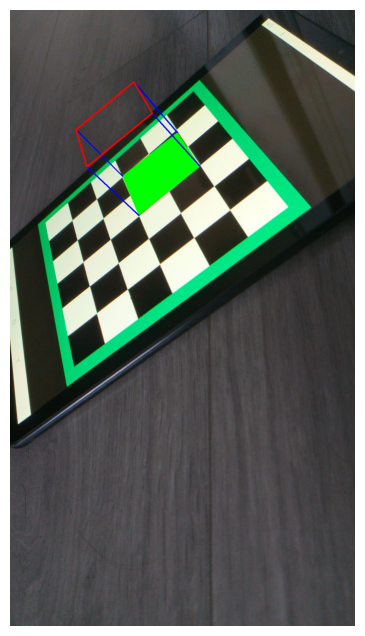

In [ ]:
# Fonction pour dessiner un cube 3D (tirée du tutoriel OpenCV py_pose)
def draw_cube(img, corners, imgpts):
    imgpts = np.int32(imgpts).reshape(-1, 2)
    
    # Dessiner la base (sol) en vert
    img = cv2.drawContours(img, [imgpts[:4]], -1, (0,255,0), -3)
    
    # Dessiner les piliers en bleu
    for i, j in zip(range(4), range(4,8)):
        img = cv2.line(img, tuple(imgpts[i]), tuple(imgpts[j]), (255,0,0), 3)
        
    # Dessiner le toit en rouge
    img = cv2.drawContours(img, [imgpts[4:]], -1, (0,0,255), 3)
    return img

# Définir les 8 sommets d'un cube 3D (taille = 2 carrés de l'échiquier)
# Le Z est négatif pour que le cube "sorte" de la tablette vers la caméra
axis_cube = np.float32([[0,0,0], [0,2,0], [2,2,0], [2,0,0],
                        [0,0,-2], [0,2,-2], [2,2,-2], [2,0,-2]]) * taille_carre_m

# Prendre une image valide au hasard (par exemple la première de la liste validée)
test_image_path = images[15] # Test effectué avec plusieurs index
img_pose = cv2.imread(test_image_path)
gray_pose = cv2.cvtColor(img_pose, cv2.COLOR_BGR2GRAY)

ret, corners = cv2.findChessboardCorners(gray_pose, (colonnes_internes, lignes_internes), None)

if ret:
    corners2 = cv2.cornerSubPix(gray_pose, corners, (11, 11), (-1, -1),
                                (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001))
    
    # Calcul de la pose (solvePnP) pour cette image spécifique
    ret_pnp, rvec, tvec = cv2.solvePnP(objp, corners2, mtx, dist)
    # ret_pnp, rvec, tvec = cv2.solvePnP(objp, corners2, mtx, dist, flags=cv2.SOLVEPNP_EPNP) # test de ce flag cv2.SOLVEPNP_EPNP
    
    # Projeter les points 3D du cube sur l'image 2D
    imgpts, jac = cv2.projectPoints(axis_cube, rvec, tvec, mtx, dist)
    
    # Dessiner le cube
    img_pose = draw_cube(img_pose, corners2, imgpts)
    
    # Sauvegarder et afficher
    cv2.imwrite('pose_cube.jpg', img_pose)
    print("Image avec le cube 3D sauvegardée sous 'pose_cube.jpg'")
    
    # Affichage dans le notebook
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(img_pose, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()
else:
    print("Échec de la détection pour l'estimation de pose.")